# 6. Pipeline completo: reposo (sin música) vs música nativa

En este notebook tomamos todo el análisis que armamos en los notebooks previos (1 a 4) y los aplica a una nueva comparación:

| Condición | Carpeta | Experimento | Archivos |
|---|---|---|---|
| **Reposo** (sin música) | `datos/Segmented_Data_2/Sin música ojos cerrados` | ex02: reposo con **ojos cerrados**, 3 sesiones por sujeto | 60 |
| **Música nativa** | `datos/Segmented_Data_2/Con música nativa` | ex05: canción en idioma nativo, auriculares | 20 |

El código es el mismo de los notebooks anteriores, con tres cambios:
1. Partimos de las señales segmentadas sin filtrar, así que primero se aplica `eeg.aplicar_filtros_eeg` (el mismo filtro del notebook 02).
2. Las condiciones ahora son `reposo` y `musica`, y **Δ = música − reposo** (Δ > 0 = más potencia escuchando música).
3. Las **3 sesiones de reposo se promedian** para tener un solo valor de reposo representativo por sujeto (sección 6.3).

Los resultados se guardan en `resultados_reposo_musica/`, así no pisan los del análisis nativo vs no nativo.

## 6.1 Descriptores usados

| Descriptor | Qué cambia en la interpretación |
|---|---|
| **Potencia absoluta** $P_{abs}$ | Cuánta energía hay en cada ritmo en reposo y con música |
| **Potencia relativa** $P_{rel}$ | Cómo se **reparte** la potencia. **Cuidado:** acá la δ cambia mucho entre condiciones, y como las bandas suman 1, una caída de δ hace subir **todas** las demás en relativa aunque no hayan cambiado. Siempre hay que mirarla junto con la absoluta |
| **Diferencia pareada** Δ | Ahora Δ = música − reposo: es "el cambio que produce escuchar la canción" respecto del reposo |
| **Tamaño de efecto** $d_z$ | Igual que antes: el cambio medio en unidades de desvío entre sujetos |

Las definiciones completas y las fórmulas están en el notebook 04 (sección 4.0) y los conceptos de estadística en el notebook 05 (sección 7.0).

**Por qué ojos cerrados.** Con el reposo de ojos abiertos (ex01) la α con música salía el doble, pero abrir los ojos baja mucho la α (Barry et al., 2007), así que esa comparación mezclaba "música" con "ojos". Por eso la referencia ahora es el reposo con **ojos cerrados (ex02)**. En 8.4 se comparan los tres estados.

## 6.2 Configuración

In [36]:
import os, sys, glob, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as ss
from scipy import stats
from scipy.optimize import brentq
import warnings
warnings.filterwarnings('ignore', message='Mean of empty slice')

sys.path.append(os.path.abspath('..'))
import procesamiento_eeg as eeg

RUTA_REPOSO = '../datos/Segmented_Data_2/Sin música ojos cerrados'
RUTA_REPOSO_OA = '../datos/Segmented_Data_2/Sin música ojos abiertos'   # solo para la comparación de 8.4
RUTA_MUSICA = '../datos/Segmented_Data_2/Con música nativa'
RUTA_META   = '../datos'
RUTA_OUT    = '../resultados_reposo_musica'
os.makedirs(RUTA_OUT, exist_ok=True)

EXP_REPOSO = 'ex02'          # reposo ojos cerrados (ex01 = ojos abiertos)
EXP_MUSICA = 'ex05'          # canción nativa con auriculares

FS = 200
NPERSEG = 4000               # 20 s, igual que en el paso 5
NOVERLAP = NPERSEG // 2      # 50 %
MIN_MUESTRAS = 18000         # mismo criterio del control de calidad (90 s)
CANALES = ['T7', 'F8', 'Cz', 'P4']
CONDICIONES = ['reposo', 'musica']   # Δ = musica − reposo
BANDAS = {
    'delta': (0.5, 4),
    'theta': (4, 8),
    'alfa':  (8, 13),
    'beta':  (13, 30),
    'gamma': (30, 40),
}
RANGO_TOTAL = (0.5, 40)
SUJETOS_EXCLUIDOS = ['s19']  # mismo criterio que antes: lengua materna ambigua → no es seguro que ex05 sea "nativa"
GUARDAR_FILTRADOS = False    # True para guardar los CSV filtrados (como en el notebook 02)

BANDAS_L = list(BANDAS)
CELDAS = [(c, b) for c in CANALES for b in BANDAS_L]
rng = np.random.default_rng(2026)
pd.set_option('display.width', 200)

## 6.3 Paso 1–2: inventario y control de calidad

Se extraen todos los archivos de las dos carpetas y se les aplica `eeg.verificar_calidad_csv` (la misma función del notebook 01). Chequea que no estén vacíos, que no tengan NaN ni infinitos y que tengan al menos 18 000 muestras (90 s).

*Nota sobre el código del grupo:* `verificar_calidad_csv` toma los canales como `df.columns[1:]`, pero como `cargar_registro` ya usa la primera columna como índice, eso **saltea el canal T7** en los chequeos de NaN e infinitos. Por eso abajo se agrega un chequeo extra sobre los 4 canales.

In [37]:
def inventario():
    filas = []
    for cond, ruta, patron in [('reposo', RUTA_REPOSO, f'*_{EXP_REPOSO}_s*.csv'),
                               ('musica', RUTA_MUSICA, f'*_{EXP_MUSICA}.csv')]:
        for path in sorted(glob.glob(os.path.join(ruta, patron))):
            nombre = os.path.basename(path)
            partes = nombre.replace('.csv', '').split('_')
            valido, motivo = eeg.verificar_calidad_csv(path, MIN_MUESTRAS)
            df = eeg.cargar_registro(path)
            if valido and (df[CANALES].isnull().any().any() or not np.isfinite(df[CANALES].values).all()):
                valido, motivo = False, 'NaN/inf en algún canal'
            filas.append({'archivo': nombre, 'ruta': path, 'sujeto': partes[0], 'condicion': cond,
                          'sesion': partes[2] if len(partes) > 2 else '-',
                          'duracion_s': len(df) / FS, 'valido': valido, 'observacion': motivo or 'OK'})
    return pd.DataFrame(filas)

inv = inventario()
inv['excluido_sujeto'] = inv.sujeto.isin(SUJETOS_EXCLUIDOS)
print(inv.groupby('condicion').size().to_string())
print('\nArchivos que NO pasan el control de calidad:')
display(inv[~inv.valido][['archivo', 'duracion_s', 'observacion']])
print('Duraciones distintas de 120 s:')
display(inv[(inv.duracion_s - 120).abs() > 1][['archivo', 'duracion_s', 'valido']])
inv.drop(columns='ruta').to_csv(os.path.join(RUTA_OUT, 'inventario_calidad.csv'), index=False)

condicion
musica    20
reposo    60

Archivos que NO pasan el control de calidad:


,archivo,duracion_s,observacion


Duraciones distintas de 120 s:


,archivo,duracion_s,valido
64,s05_ex05.csv,200.57,True


**Resumen.** Los 80 archivos pasan el control.

### Metadatos (igual que en el notebook 04)

In [38]:
meta = pd.read_csv(os.path.join(RUTA_META, 'Subjects.csv'))
meta.columns = meta.columns.str.strip()
meta['sujeto'] = meta['Subject ID'].str.strip().str.lower()
meta['idioma_nativo'] = meta['Mother Language'].str.strip()
meta['grupo'] = meta['idioma_nativo'].map(lambda x: {'Italian': 'italiano', 'Arabic': 'arabe'}.get(x, 'otro'))
meta = meta[~meta.sujeto.isin(SUJETOS_EXCLUIDOS)].reset_index(drop=True)
meta_cols = ['sujeto', 'idioma_nativo', 'grupo']
sujetos = meta.sujeto.tolist()
print(f'{len(sujetos)} sujetos:', meta.grupo.value_counts().to_dict())

19 sujetos: {'arabe': 8, 'italiano': 7, 'otro': 4}


## 6.4 Paso 3–4: filtrado y PSD de Welch

Para cada archivo válido:
1. **Filtrado** con `eeg.aplicar_filtros_eeg` (notch 50 Hz + pasabanda Butterworth 0,1–40 Hz de orden 4, fase cero). Es exactamente el mismo filtro del notebook 02: se verificó que para `s01_ex05` reproduce `Datos_Filtrados` con una diferencia de ~10⁻⁹ µV.
2. **PSD de Welch** con los mismos parámetros del paso 5 (Hann de 20 s, 50 % de solapamiento, µV²/Hz).

Para el reposo se guarda la PSD de **cada sesión** (`PSD_SES`, para el análisis de 8.1–8.3) y su **promedio por sujeto** (`PSD`, que es la que se usa en todo el resto).

In [39]:
def psd_archivo(path):
    df = eeg.cargar_registro(path)
    df_f = eeg.aplicar_filtros_eeg(df, fs=FS)
    if GUARDAR_FILTRADOS:
        carpeta = os.path.join(os.path.dirname(path) + '_filtrado')
        os.makedirs(carpeta, exist_ok=True)
        df_f.to_csv(os.path.join(carpeta, os.path.basename(path)))
    filas = []
    for ch in CANALES:
        f, pxx = ss.welch(df_f[ch].to_numpy(float), fs=FS, window='hann', nperseg=NPERSEG,
                          noverlap=NOVERLAP, detrend='constant', scaling='density')
        filas.append(pxx)
    return f, np.array(filas)                      # (canal, frecuencia)

usar = inv[inv.valido & ~inv.excluido_sujeto]
NF = NPERSEG // 2 + 1
PSD = np.full((len(sujetos), len(CONDICIONES), len(CANALES), NF), np.nan)
SESIONES = ['s01', 's02', 's03']
PSD_SES = np.full((len(sujetos), len(SESIONES), len(CANALES), NF), np.nan)
n_ses = {}

for i, s in enumerate(sujetos):
    # música
    r = usar[(usar.sujeto == s) & (usar.condicion == 'musica')]
    freq, PSD[i, 1] = psd_archivo(r.ruta.item())
    # reposo: cada sesión válida, después el promedio
    r = usar[(usar.sujeto == s) & (usar.condicion == 'reposo')]
    for _, fila in r.iterrows():
        _, PSD_SES[i, SESIONES.index(fila.sesion)] = psd_archivo(fila.ruta)
    PSD[i, 0] = np.nanmean(PSD_SES[i], axis=0)
    n_ses[s] = len(r)

assert not np.isnan(PSD).any()
print('Forma de PSD (sujeto, condición, canal, frecuencia):', PSD.shape)
print('Sesiones de reposo promediadas por sujeto:', {k: v for k, v in n_ses.items() if v != 3} or 'todas 3')
np.savez_compressed(os.path.join(RUTA_OUT, 'psd_por_sujeto.npz'), freq=freq, psd=PSD, psd_sesiones=PSD_SES,
                    sujetos=np.array(sujetos), condiciones=np.array(CONDICIONES), canales=np.array(CANALES))

Forma de PSD (sujeto, condición, canal, frecuencia): (19, 2, 4, 2001)
Sesiones de reposo promediadas por sujeto: todas 3


### PSD típica por canal: reposo vs música
Mediana entre sujetos (línea) y rango intercuartil (sombra). Igual que en el notebook 04.

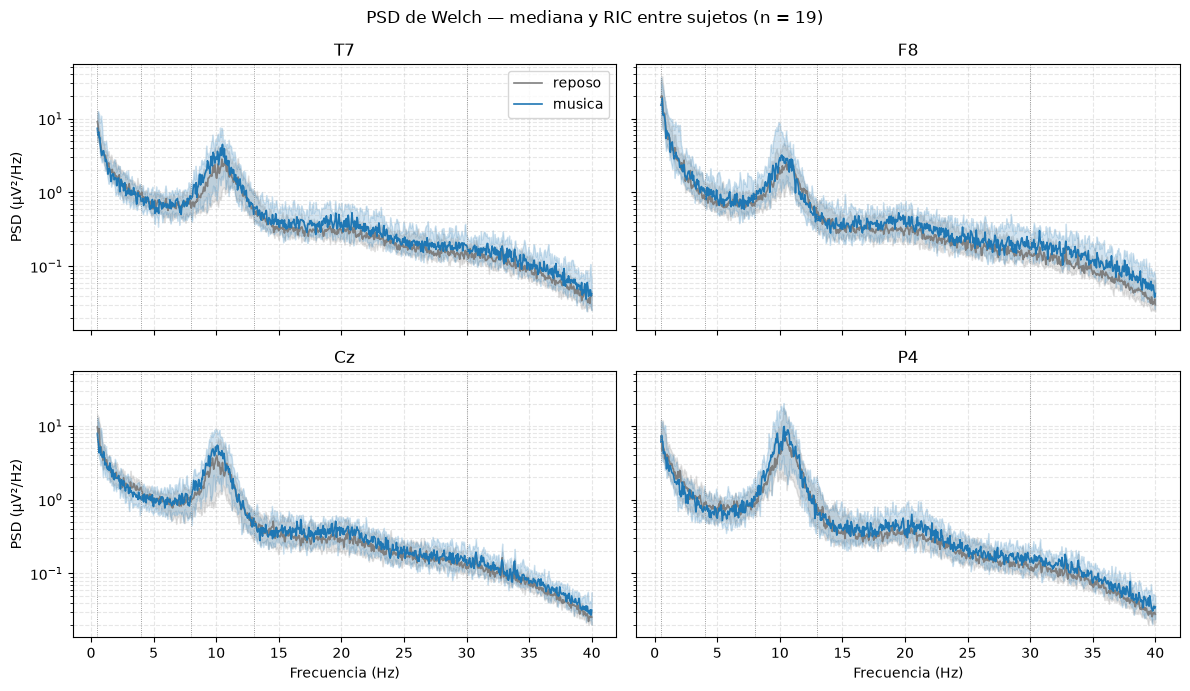

In [40]:
colores = {'reposo': 'tab:gray', 'musica': 'tab:blue'}
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
m = (freq >= 0.5) & (freq <= 40)
for ax, (k, ch) in zip(axes.flat, enumerate(CANALES)):
    for j, cond in enumerate(CONDICIONES):
        x = PSD[:, j, k][:, m]
        ax.semilogy(freq[m], np.median(x, 0), color=colores[cond], lw=1.2, label=cond)
        ax.fill_between(freq[m], *np.percentile(x, [25, 75], 0), color=colores[cond], alpha=0.2)
    for lo, hi in BANDAS.values():
        ax.axvline(lo, color='gray', lw=0.6, ls=':')
    ax.set_title(ch); ax.grid(True, which='both', ls='--', alpha=0.3)
for ax in axes[1]: ax.set_xlabel('Frecuencia (Hz)')
for ax in axes[:, 0]: ax.set_ylabel('PSD (µV²/Hz)')
axes[0, 0].legend()
fig.suptitle(f'PSD de Welch — mediana y RIC entre sujetos (n = {len(sujetos)})')
plt.tight_layout(); plt.show()

**Resumen.** Las curvas de reposo y música casi se superponen. La única diferencia visible es un **pico de α (~10 Hz) un poco más alto con música**, sobre todo en Cz y P4.

## 6.5 Paso 5: potencia absoluta y relativa por banda
Mismo cálculo que en el notebook 04: suma de rectángulos $\sum \text{PSD}\cdot\Delta f$ en intervalos $[f_1, f_2)$, y relativa = banda / total (0,5–40 Hz).

In [41]:
df_f = freq[1] - freq[0]

def potencia(psd, lo, hi, incluir_hi=False):
    m = (freq >= lo) & ((freq <= hi) if incluir_hi else (freq < hi))
    return psd[..., m].sum(axis=-1) * df_f

P_total = potencia(PSD, *RANGO_TOTAL, incluir_hi=True)
filas = []
for b, (lo, hi) in BANDAS.items():
    P_b = potencia(PSD, lo, hi, incluir_hi=(hi == RANGO_TOTAL[1]))
    for i, s in enumerate(sujetos):
        for j, cond in enumerate(CONDICIONES):
            for k, ch in enumerate(CANALES):
                filas.append(dict(sujeto=s, condicion=cond, canal=ch, banda=b, p_abs=P_b[i, j, k],
                                  p_total=P_total[i, j, k], p_rel=P_b[i, j, k] / P_total[i, j, k]))
pot = pd.DataFrame(filas).merge(meta[meta_cols], on='sujeto')
pot['log10_p_abs'] = np.log10(pot.p_abs)
assert np.allclose(pot.groupby(['sujeto', 'condicion', 'canal'])['p_rel'].sum(), 1)
pot.to_csv(os.path.join(RUTA_OUT, 'potencia_bandas_largo.csv'), index=False)

print('Potencia relativa, mediana entre sujetos (%):')
display((pot.pivot_table(index=['canal', 'condicion'], columns='banda', values='p_rel', aggfunc='median')
         * 100).reindex(columns=BANDAS_L).reindex(CANALES, level=0).round(1))
print('Potencia absoluta, mediana entre sujetos (µV²):')
display(pot.pivot_table(index=['canal', 'condicion'], columns='banda', values='p_abs', aggfunc='median')
        .reindex(columns=BANDAS_L).reindex(CANALES, level=0).round(2))

Potencia relativa, mediana entre sujetos (%):


banda            delta  theta  alfa  beta  gamma
canal condicion                                 
T7    musica      29.4    9.8  32.8  20.4    4.1
      reposo      32.8   11.3  29.5  19.9    4.2
F8    musica      40.3    8.7  21.9  15.7    3.5
      reposo      43.2    8.1  24.8  13.0    2.9
Cz    musica      27.9   11.7  38.9  16.4    2.6
      reposo      34.0   13.0  32.6  15.8    2.4
P4    musica      18.3    8.0  56.7  15.6    2.5
      reposo      25.7    8.9  49.3  13.4    1.9

Potencia absoluta, mediana entre sujetos (µV²):


banda            delta  theta   alfa  beta  gamma
canal condicion                                  
T7    musica      6.15   3.03  12.22  5.63   1.25
      reposo      7.39   3.02   9.44  4.50   0.93
F8    musica     13.72   3.24  10.12  5.47   1.35
      reposo     14.13   3.03   8.04  4.48   0.89
Cz    musica      9.00   4.39  13.84  5.92   0.91
      reposo     10.16   4.24   8.95  4.60   0.77
P4    musica      7.10   2.88  22.37  6.65   0.95
      reposo      8.22   3.38  17.65  4.80   0.78

**Resumen.** Con música, la α relativa sube un poco en T7, Cz y P4 (P4: 49 % → 57 %) y la δ baja algo. En absoluta, casi **todas** las bandas suben con música, no solo α.

### Diferencia pareada y tamaño de efecto
- `d_log_abs` = $\log_{10}(P^{música}/P^{reposo})$; `cambio_abs_pct` = $(10^{\Delta}-1)\cdot 100$.
- `d_rel_pp` = diferencia de potencia relativa en puntos porcentuales.
- $d_z$ = media(Δ) / desvío(Δ), con IC 95 % por bootstrap (5000 réplicas) y % de sujetos con Δ > 0.

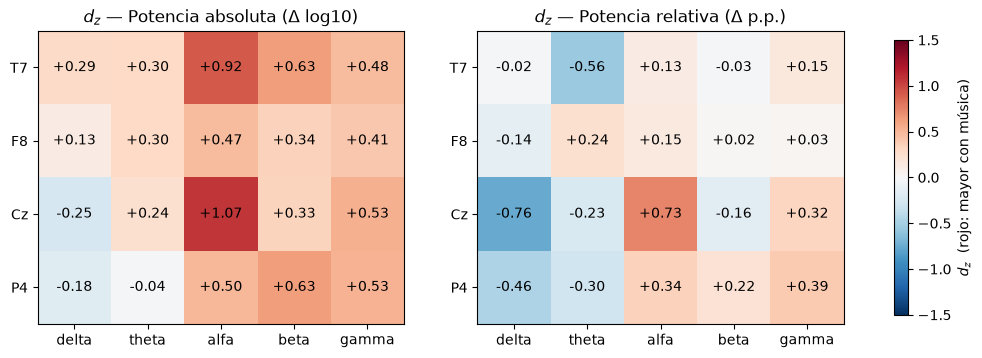

In [42]:
idx = ['sujeto', 'canal', 'banda']
w_log = pot.pivot_table(index=idx, columns='condicion', values='log10_p_abs')
w_rel = pot.pivot_table(index=idx, columns='condicion', values='p_rel')
dif = pd.DataFrame({'d_log_abs': w_log['musica'] - w_log['reposo'],
                    'd_rel_pp': (w_rel['musica'] - w_rel['reposo']) * 100}).reset_index()
dif['cambio_abs_pct'] = (10 ** dif.d_log_abs - 1) * 100
dif = dif.merge(meta[meta_cols], on='sujeto')
dif.to_csv(os.path.join(RUTA_OUT, 'diferencias_por_sujeto.csv'), index=False)

N_BOOT = 5000
def resumen(x):
    x = np.asarray(x, float)
    boot = rng.choice(x, size=(N_BOOT, len(x)), replace=True)
    lo, hi = np.nanpercentile(boot.mean(1) / boot.std(1, ddof=1), [2.5, 97.5])
    return pd.Series({'n': len(x), 'media': x.mean(), 'desvio': x.std(ddof=1), 'dz': x.mean() / x.std(ddof=1),
                      'dz_ic_inf': lo, 'dz_ic_sup': hi, 'pct_sujetos_pos': 100 * (x > 0).mean()})

VARS = {'d_log_abs': 'Potencia absoluta (Δ log10)', 'd_rel_pp': 'Potencia relativa (Δ p.p.)'}
efe = []
for v in VARS:
    r = dif.groupby(['canal', 'banda'])[v].apply(resumen).unstack(); r['descriptor'] = v
    efe.append(r.reset_index())
efe = pd.concat(efe, ignore_index=True)
efe.to_csv(os.path.join(RUTA_OUT, 'tamano_efecto.csv'), index=False)

X = {v: dif.pivot_table(index='sujeto', columns=['canal', 'banda'], values=v)[CELDAS].loc[sujetos] for v in VARS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, v in zip(axes, VARS):
    M = efe[efe.descriptor == v].pivot(index='canal', columns='banda', values='dz').reindex(index=CANALES, columns=BANDAS_L)
    im = ax.imshow(M.values, cmap='RdBu_r', vmin=-1.5, vmax=1.5)
    for a in range(4):
        for b in range(5):
            ax.text(b, a, f'{M.values[a, b]:+.2f}', ha='center', va='center', fontsize=10)
    ax.set_xticks(range(5), BANDAS_L); ax.set_yticks(range(4), CANALES); ax.set_title(f'$d_z$ — {VARS[v]}')
fig.colorbar(im, ax=axes, shrink=0.85, label='$d_z$  (rojo: mayor con música)')
plt.show()

**Resumen.** Los efectos más grandes son en **α absoluta** (Cz 1,07; T7 0,92). En relativa casi todo es chico, salvo α en Cz (+0,73) y δ en Cz (−0,76).

## 6.6 Paso 7: tests estadísticos

Exactamente el mismo procedimiento del notebook 05 (conceptos en la sección 7.0 de ese notebook):
1. **Normalidad** de los Δ (Shapiro-Wilk), para justificar el test.
2. **Wilcoxon pareado** (principal) y **t pareado** (complemento) en cada canal × banda.
3. **Corrección por comparaciones múltiples:** FDR (Benjamini-Hochberg), Holm y permutación max-T.

In [43]:
def holm(p):
    p = np.asarray(p, float); m = len(p); orden = np.argsort(p)
    ajust = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[orden]))
    salida = np.empty(m); salida[orden] = ajust
    return salida

def t_stat(M):
    n = M.shape[-2]
    return M.mean(-2) / (M.std(-2, ddof=1) / np.sqrt(n))

def maxT(M, n_perm=20000):
    M = np.asarray(M, float); t_obs = t_stat(M)
    t_perm = t_stat(rng.choice([-1.0, 1.0], size=(n_perm, M.shape[0], 1)) * M[None])
    return (np.abs(t_perm) >= np.abs(t_obs)).mean(0), (np.abs(t_perm).max(1)[:, None] >= np.abs(t_obs)).mean(0)

filas = []
for v in VARS:
    for (c, b) in CELDAS:
        x = X[v][(c, b)].values
        filas.append({'descriptor': v, 'canal': c, 'banda': b, 'media_delta': x.mean(),
                      'shapiro_p': stats.shapiro(x).pvalue,
                      'p_wilcoxon': stats.wilcoxon(x).pvalue, 'p_t': stats.ttest_1samp(x, 0).pvalue})
tests = pd.DataFrame(filas).merge(efe[['descriptor', 'canal', 'banda', 'dz', 'dz_ic_inf', 'dz_ic_sup', 'pct_sujetos_pos']],
                                  on=['descriptor', 'canal', 'banda'])
for v in VARS:
    m = tests.descriptor == v
    tests.loc[m, 'p_fdr'] = stats.false_discovery_control(tests.loc[m, 'p_wilcoxon'])
    tests.loc[m, 'p_holm'] = holm(tests.loc[m, 'p_wilcoxon'])
    tests.loc[m, 'p_perm'], tests.loc[m, 'p_maxT'] = maxT(X[v].values)
tests['signif_fdr'] = tests.p_fdr < .05
tests.to_csv(os.path.join(RUTA_OUT, 'tests_paso7.csv'), index=False)

print('Celdas donde se rechaza la normalidad:', tests.groupby('descriptor')['shapiro_p'].apply(lambda s: f'{(s<.05).sum()}/20').to_dict())
print('Celdas significativas tras FDR:', tests.groupby('descriptor')['signif_fdr'].sum().to_dict())
cols = ['descriptor', 'canal', 'banda', 'media_delta', 'dz', 'dz_ic_inf', 'dz_ic_sup', 'pct_sujetos_pos',
        'p_wilcoxon', 'p_fdr', 'p_holm', 'p_maxT']
display(tests[tests.signif_fdr][cols].sort_values(['descriptor', 'p_wilcoxon']).round(4))

Celdas donde se rechaza la normalidad: {'d_log_abs': '15/20', 'd_rel_pp': '11/20'}
Celdas significativas tras FDR: {'d_log_abs': 7, 'd_rel_pp': 1}


,descriptor,canal,banda,media_delta,dz,dz_ic_inf,dz_ic_sup,pct_sujetos_pos,p_wilcoxon,p_fdr,p_holm,p_maxT
12,d_log_abs,Cz,alfa,0.1332,1.0678,0.7086,1.6956,78.9474,0.0003,0.0064,0.0067,0.0004
2,d_log_abs,T7,alfa,0.1119,0.9189,0.5089,1.6987,84.2105,0.0006,0.0064,0.0122,0.0021
18,d_log_abs,P4,beta,0.0856,0.6310,0.1583,1.3728,89.4737,0.0014,0.0085,0.0254,0.0686
7,d_log_abs,F8,alfa,0.1546,0.4735,0.0823,1.6771,84.2105,0.0017,0.0085,0.0288,0.3604
3,d_log_abs,T7,beta,0.1011,0.6260,0.3692,1.0755,84.2105,0.0053,0.0213,0.0853,0.0729
14,d_log_abs,Cz,gamma,0.0840,0.5291,0.2840,1.0921,73.6842,0.0071,0.0238,0.1072,0.2141
17,d_log_abs,P4,alfa,0.1031,0.5013,0.0418,1.1220,68.4211,0.0124,0.0353,0.1730,0.2822
30,d_rel_pp,Cz,delta,-5.6902,-0.7584,-1.5817,-0.2814,15.7895,0.0017,0.0339,0.0339,0.0177


**Resumen.** En absoluta, 7 de 20 celdas dan significativo con FDR: α en T7, F8, Cz y P4, β en T7 y P4, y γ en Cz. Las únicas que pasan **todas** las correcciones son **α en Cz y T7**. En relativa solo sobrevive **δ en Cz** (baja con música).

### ¿Cambia solo α o toda la señal?
Si con música sube la potencia de **todas** las bandas por igual (por ejemplo, por un cambio de amplitud del registro), la α absoluta sube aunque la α no tenga nada especial. Para separar eso se resta el cambio de la potencia total: **Δ(banda) − Δ(total)**. Si sigue siendo > 0, esa banda sube **más que el resto de la señal**.

In [44]:
tot = pot[pot.banda == 'delta'].pivot_table(index=['sujeto', 'canal'], columns='condicion', values='p_total')
d_tot = (np.log10(tot.musica) - np.log10(tot.reposo)).rename('d_tot').reset_index()
filas = []
for (c, b) in CELDAS:
    x = X['d_log_abs'][(c, b)]
    t = d_tot[d_tot.canal == c].set_index('sujeto').loc[x.index, 'd_tot']
    filas.append({'canal': c, 'banda': b, 'Δ banda': x.mean(), 'Δ total': t.mean(),
                  'Δ banda − Δ total': (x - t).mean(), 'p': stats.wilcoxon(x - t).pvalue})
espec = pd.DataFrame(filas); espec['p_fdr'] = stats.false_discovery_control(espec.p)
espec.to_csv(os.path.join(RUTA_OUT, 'especificidad_banda.csv'), index=False)
print('Potencia TOTAL (música − reposo), media Δ log10 por canal:', d_tot.groupby('canal').d_tot.mean().reindex(CANALES).round(3).to_dict())
display(espec[espec.banda == 'alfa'].round(3))

Potencia TOTAL (música − reposo), media Δ log10 por canal: {'T7': 0.119, 'F8': 0.127, 'Cz': 0.052, 'P4': 0.034}


,canal,banda,Δ banda,Δ total,Δ banda − Δ total,p,p_fdr
2,T7,alfa,0.112,0.119,-0.007,0.465,0.811
7,F8,alfa,0.155,0.127,0.028,0.312,0.738
12,Cz,alfa,0.133,0.052,0.081,0.011,0.054
17,P4,alfa,0.103,0.034,0.069,0.332,0.738


**Resumen.** Con música sube la potencia de **toda la señal** (T7 y F8 ≈ +30 %). Descontado eso, la α de T7, F8 y P4 **no sube más que el resto**. Solo en **Cz** la α sube por encima de la señal total (≈ +20 %, p = 0,011), pero queda **justo en el límite** después de corregir (FDR = 0,054). Así que el aumento "en todas las bandas" de la tabla anterior es en gran parte un aumento global.

### Paso 6: Diferencias en los electrodos (¿son significativas?) ¿El efecto de la música depende del electrodo?
Mismo test de Friedman que en el notebook 05: (a) topografía de la potencia relativa dentro de cada condición y (b) **interacción**, es decir, si los Δ de los 4 electrodos son intercambiables.

In [47]:
filas = []
for cond in CONDICIONES:
    for b in BANDAS_L:
        M = pot[(pot.banda == b) & (pot.condicion == cond)].pivot(index='sujeto', columns='canal', values='p_rel')[CANALES]
        filas.append({'condicion': cond, 'banda': b, 'p_friedman': stats.friedmanchisquare(*M.T.values).pvalue,
                      **{f'{c} (%)': 100 * M[c].median() for c in CANALES}})
topo = pd.DataFrame(filas); topo['p_fdr'] = stats.false_discovery_control(topo.p_friedman)
print('(a) Diferencias entre electrodos (potencia relativa, mediana %):'); display(topo.round(4))

filas = []
for v in VARS:
    for b in BANDAS_L:
        M = X[v].xs(b, axis=1, level='banda')[CANALES]
        filas.append({'descriptor': v, 'banda': b, 'p_friedman': stats.friedmanchisquare(*M.T.values).pvalue,
                      **{f'media Δ {c}': M[c].mean() for c in CANALES}})
inter = pd.DataFrame(filas)
inter['p_fdr'] = inter.groupby('descriptor')['p_friedman'].transform(stats.false_discovery_control)
print('(b) ¿El Δ (música − reposo) depende del electrodo?'); display(inter.round(3))

(a) Diferencias entre electrodos (potencia relativa, mediana %):


,condicion,banda,p_friedman,T7 (%),F8 (%),Cz (%),P4 (%),p_fdr
0,reposo,delta,0.0000,32.8064,43.2419,34.0388,25.6597,0.0000
1,reposo,theta,0.0000,11.2779,8.1480,13.0398,8.9410,0.0000
2,reposo,alfa,0.0000,29.5096,24.7687,32.6147,49.2700,0.0000
3,reposo,beta,0.0009,19.9413,12.9579,15.8459,13.4365,0.0013
4,reposo,gamma,0.0011,4.1885,2.9158,2.4184,1.9332,0.0014
5,musica,delta,0.0000,29.4296,40.2692,27.9109,18.2643,0.0000
6,musica,theta,0.0000,9.8414,8.6800,11.7036,7.9651,0.0001
7,musica,alfa,0.0000,32.7731,21.9242,38.8815,56.7258,0.0000
8,musica,beta,0.0155,20.4078,15.7326,16.3868,15.5606,0.0155
9,musica,gamma,0.0130,4.1021,3.5352,2.6050,2.4659,0.0145


(b) ¿El Δ (música − reposo) depende del electrodo?


,descriptor,banda,p_friedman,media Δ T7,media Δ F8,media Δ Cz,media Δ P4,p_fdr
0,d_log_abs,delta,0.058,0.090,0.088,-0.040,-0.068,0.290
1,d_log_abs,theta,0.345,0.056,0.154,0.025,-0.008,0.670
2,d_log_abs,alfa,0.536,0.112,0.155,0.133,0.103,0.670
3,d_log_abs,beta,0.536,0.101,0.120,0.037,0.086,0.670
4,d_log_abs,gamma,0.852,0.134,0.146,0.084,0.136,0.852
5,d_rel_pp,delta,0.363,-0.261,-2.647,-5.690,-5.701,0.606
6,d_rel_pp,theta,0.052,-1.429,0.715,-0.751,-0.833,0.192
7,d_rel_pp,alfa,0.077,1.430,1.669,6.450,4.018,0.192
8,d_rel_pp,beta,0.984,-0.162,0.161,-0.705,1.444,0.984
9,d_rel_pp,gamma,0.984,0.422,0.101,0.697,1.073,0.984


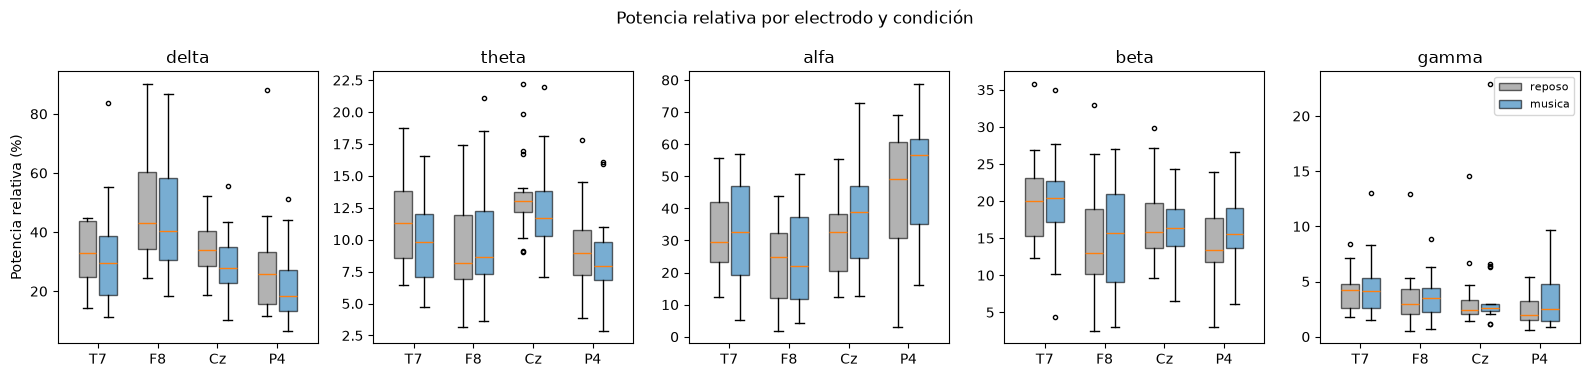

In [48]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))
for ax, b in zip(axes, BANDAS_L):
    datos, pos, cols = [], [], []
    for k, c in enumerate(CANALES):
        for j, cond in enumerate(CONDICIONES):
            datos.append(100 * pot[(pot.banda == b) & (pot.canal == c) & (pot.condicion == cond)].p_rel.values)
            pos.append(k + (j - 0.5) * 0.35); cols.append(colores[cond])
    bp = ax.boxplot(datos, positions=pos, widths=0.3, patch_artist=True, flierprops=dict(markersize=3))
    for patch, col in zip(bp['boxes'], cols): patch.set_facecolor(col); patch.set_alpha(0.6)
    ax.set_xticks(range(4), CANALES); ax.set_title(b)
axes[0].set_ylabel('Potencia relativa (%)')
axes[-1].legend([bp['boxes'][0], bp['boxes'][1]], CONDICIONES, fontsize=8)
fig.suptitle('Potencia relativa por electrodo y condición'); plt.tight_layout(); plt.show()

**Resumen.** (a) Los electrodos difieren mucho entre sí, como siempre (α máxima en P4). (b) El efecto de la música **no depende del electrodo** (ningún p corregido < 0,05).

# Paso 8 — Análisis exploratorio y limitaciones

En la comparación nativo vs no nativo, el paso 8 trataba de **familiaridad con el idioma**. Acá la música es siempre la nativa, así que esa pregunta ya no aplica. Pero las 3 sesiones de reposo permiten preguntas nuevas, y algunas son clave para interpretar el paso 7:

- **8.1** ¿El cambio con música es mayor que la variabilidad natural entre sesiones de reposo? (piso de ruido)
- **8.2** ¿Cambia el resultado si se usa una sola sesión en lugar del promedio? (justifica la decisión de 6.0)
- **8.3** ¿El EEG cambia solo con el paso del tiempo? (efecto de orden)
- **8.4** ¿Los ojos abiertos explican el efecto? (el confusor principal)
- **8.5** ¿El efecto depende de la canción (grupo de idioma)?

## 8.1 Piso de ruido: variabilidad entre sesiones de reposo vs efecto de la música

**Idea.** Las 3 sesiones de reposo son **la misma condición**, así que cualquier diferencia entre ellas es "ruido" (variabilidad natural del EEG, cambios de electrodo, de estado). Si el cambio música a reposo es **parecido** a la diferencia entre sesión y sesión, la música no está haciendo nada distinto de lo que pasa entre dos reposos. Si es **mucho mayor**, el efecto supera al ruido.

**Cálculo.** Para cada sujeto, canal y banda:
- **Ruido:** |Δ entre sesiones| = promedio de |log P(sesión a) − log P(sesión b)| sobre los pares de sesiones.
- **Efecto:** |Δ música − reposo| (el reposo es el promedio).

Se compara con Wilcoxon pareado (sujeto a sujeto) si el efecto supera al ruido.

,canal,banda,ruido_mediana,efecto_mediana,cociente,p_efecto_mayor_que_ruido,p_fdr
0,T7,delta,0.092,0.084,0.908,0.340,0.425
1,F8,delta,0.152,0.132,0.866,0.198,0.304
2,Cz,delta,0.103,0.072,0.698,0.675,0.710
3,P4,delta,0.101,0.050,0.498,0.791,0.791
4,T7,theta,0.054,0.045,0.834,0.245,0.350
5,F8,theta,0.059,0.118,2.013,0.020,0.109
6,Cz,theta,0.051,0.054,1.076,0.091,0.182
7,P4,theta,0.062,0.075,1.210,0.646,0.710
8,T7,alfa,0.092,0.123,1.344,0.084,0.182
9,F8,alfa,0.081,0.131,1.618,0.052,0.154


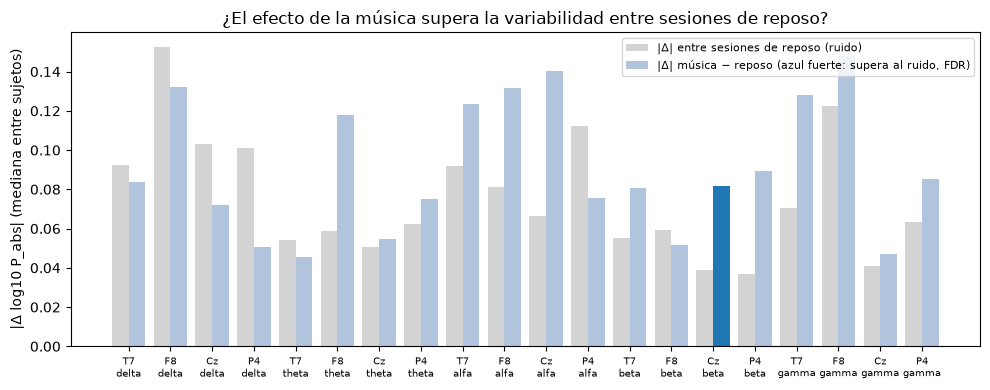

In [50]:
P_ses_b = {b: np.log10(potencia(PSD_SES, lo, hi, incluir_hi=(hi == 40))) for b, (lo, hi) in BANDAS.items()}
filas = []
for b in BANDAS_L:
    L = P_ses_b[b]                                              # (suj, sesión, canal), NaN si la sesión no es válida
    for k, ch in enumerate(CANALES):
        ruido = np.nanmean([np.abs(L[:, a, k] - L[:, c, k]) for a, c in itertools.combinations(range(3), 2)], axis=0)
        efecto = X['d_log_abs'][(ch, b)].abs().values
        filas.append({'canal': ch, 'banda': b, 'ruido_mediana': np.median(ruido), 'efecto_mediana': np.median(efecto),
                      'cociente': np.median(efecto) / np.median(ruido),
                      'p_efecto_mayor_que_ruido': stats.wilcoxon(efecto, ruido, alternative='greater').pvalue})
piso = pd.DataFrame(filas)
piso['p_fdr'] = stats.false_discovery_control(piso.p_efecto_mayor_que_ruido)
piso.to_csv(os.path.join(RUTA_OUT, 'paso8_piso_ruido.csv'), index=False)
display(piso.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
xx = np.arange(len(piso))
ax.bar(xx - 0.2, piso.ruido_mediana, 0.4, color='lightgray', label='|Δ| entre sesiones de reposo (ruido)')
ax.bar(xx + 0.2, piso.efecto_mediana, 0.4, color=np.where(piso.p_fdr < .05, 'tab:blue', 'lightsteelblue'),
       label='|Δ| música − reposo (azul fuerte: supera al ruido, FDR)')
ax.set_xticks(xx, [f'{c}\n{b}' for c, b in zip(piso.canal, piso.banda)], fontsize=7)
ax.set_ylabel('|Δ log10 P_abs| (mediana entre sujetos)'); ax.legend(fontsize=8)
ax.set_title('¿El efecto de la música supera la variabilidad entre sesiones de reposo?')
plt.tight_layout(); plt.show()

**Resumen.** Con ojos cerrados, el cambio con música es **parecido a la diferencia entre dos reposos** de la misma persona. Solo β en Cz lo supera claramente (FDR = 0,01). α en Cz es 2 veces el ruido, pero no llega a ser significativo (FDR = 0,11).

## 8.2 Sensibilidad: ¿qué pasa si se usa una sola sesión?

Se repite el cálculo de $d_z$ (potencia absoluta) usando como reposo **solo** la sesión 1, **solo** la 2, **solo** la 3, y el **promedio**. Si los resultados cambian mucho según la sesión elegida, quedarse con una sola sería una decisión arbitraria que cambia las conclusiones.

reposo_usado  promedio  sesión 1  sesión 2  sesión 3  rango_entre_sesiones
canal banda                                                               
T7    delta       0.29      0.21      0.44      0.27                  0.23
      theta       0.30      0.25      0.35      0.32                  0.09
      alfa        0.92      0.87      0.78      0.79                  0.09
      beta        0.63      0.46      0.78      0.64                  0.32
      gamma       0.48      0.37      0.64      0.49                  0.27
F8    delta       0.13      0.07      0.21      0.32                  0.25
      theta       0.30      0.22      0.34      0.51                  0.29
      alfa        0.47      0.36      0.52      0.70                  0.34
      beta        0.34      0.27      0.36      0.46                  0.19
      gamma       0.41      0.37      0.43      0.52                  0.14
Cz    delta      -0.25     -0.43     -0.06     -0.08                  0.37
      theta       0.24      0.15      0.44      0.19                  0.30
      alfa        1.07      0.95      0.96      0.99                  0.04
      beta        0.33      0.24      0.31      0.46                  0.21
      gamma       0.53      0.47      0.52      0.58                  0.11
P4    delta      -0.18     -0.09     -0.08      0.06                  0.15
      theta      -0.04      0.09     -0.02      0.44                  0.45
      alfa        0.50      0.71      0.38      0.65                  0.32
      beta        0.63      0.86      0.38      0.94                  0.56
      gamma       0.53      0.48      0.51      0.59                  0.11

Celdas con p < 0,05 según el reposo usado: {'promedio': 11, 'sesión 1': 7, 'sesión 2': 11, 'sesión 3': 14}


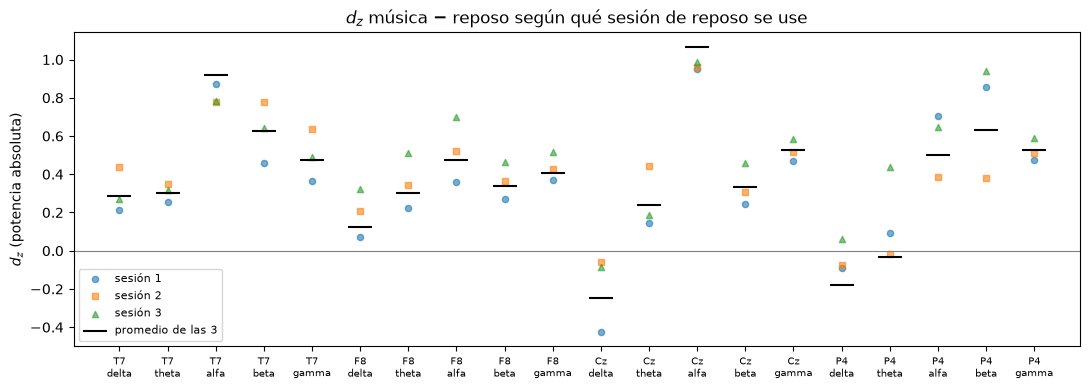

In [51]:
filas = []
for etiqueta, idx_ses in [('sesión 1', [0]), ('sesión 2', [1]), ('sesión 3', [2]), ('promedio', [0, 1, 2])]:
    for b in BANDAS_L:
        lo, hi = BANDAS[b]
        rep = np.log10(potencia(np.nanmean(PSD_SES[:, idx_ses], axis=1), lo, hi, incluir_hi=(hi == 40)))
        mus = np.log10(potencia(PSD[:, 1], lo, hi, incluir_hi=(hi == 40)))
        for k, ch in enumerate(CANALES):
            d = mus[:, k] - rep[:, k]; d = d[~np.isnan(d)]
            filas.append({'reposo_usado': etiqueta, 'canal': ch, 'banda': b, 'dz': d.mean() / d.std(ddof=1),
                          'p_wilcoxon': stats.wilcoxon(d).pvalue, 'n': len(d)})
sens = pd.DataFrame(filas)
tabla = sens.pivot_table(index=['canal', 'banda'], columns='reposo_usado', values='dz').reindex(CELDAS)
tabla['rango_entre_sesiones'] = tabla[['sesión 1', 'sesión 2', 'sesión 3']].max(axis=1) - tabla[['sesión 1', 'sesión 2', 'sesión 3']].min(axis=1)
display(tabla.round(2))
print('Celdas con p < 0,05 según el reposo usado:', sens[sens.p_wilcoxon < .05].groupby('reposo_usado').size().to_dict())

fig, ax = plt.subplots(figsize=(11, 4))
xx = np.arange(len(CELDAS))
for etiqueta, mk in [('sesión 1', 'o'), ('sesión 2', 's'), ('sesión 3', '^')]:
    ax.scatter(xx, tabla[etiqueta], marker=mk, s=20, alpha=0.6, label=etiqueta)
ax.scatter(xx, tabla['promedio'], marker='_', s=300, color='k', label='promedio de las 3')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xticks(xx, [f'{c}\n{b}' for c, b in CELDAS], fontsize=7); ax.set_ylabel('$d_z$ (potencia absoluta)')
ax.set_title('$d_z$ música − reposo según qué sesión de reposo se use'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Resumen.** α en Cz da prácticamente lo mismo con cualquier sesión (dz 0,95–1,07): ese resultado es estable. En F8 y P4 cambia bastante según la sesión que se use, y por eso conviene el promedio.

## 8.3 ¿El EEG cambia solo con el paso del tiempo?

Las 3 sesiones de reposo se registraron **una detrás de otra al principio**, y la música **más tarde** (ex05). Si a lo largo de los reposos la α sube y la δ baja (relajación, somnolencia, adaptación al laboratorio), parte del "efecto de la música" podría ser simplemente **el tiempo transcurrido**.

**Test de Friedman** sobre las 3 sesiones (mismos sujetos medidos 3 veces). Solo se usan los sujetos con las 3 sesiones válidas.

Sujetos con las 3 sesiones válidas: 19


,canal,banda,media_s1,media_s2,media_s3,cambio_s3_menos_s1,p_friedman,p_fdr
0,T7,delta,0.925,0.830,0.892,-0.033,0.443,0.739
1,F8,delta,1.300,1.206,1.148,-0.151,0.170,0.739
2,Cz,delta,1.008,0.968,0.972,-0.037,0.170,0.739
3,P4,delta,0.920,0.943,0.894,-0.026,0.887,0.911
4,T7,theta,0.465,0.445,0.449,-0.016,0.289,0.739
5,F8,theta,0.563,0.513,0.466,-0.097,0.443,0.739
6,Cz,theta,0.604,0.573,0.588,-0.016,0.253,0.739
7,P4,theta,0.504,0.520,0.467,-0.037,0.595,0.849
8,T7,alfa,0.887,0.888,0.888,0.001,0.911,0.911
9,F8,alfa,0.881,0.836,0.815,-0.066,0.297,0.739


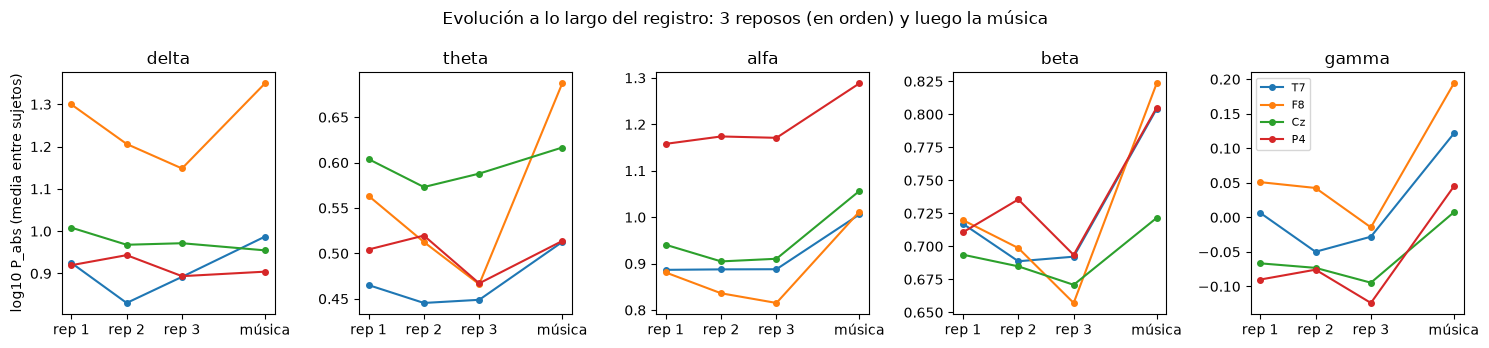

In [52]:
completos = ~np.isnan(PSD_SES[:, :, 0, 0]).any(1)
filas = []
for b in BANDAS_L:
    L = P_ses_b[b][completos]
    for k, ch in enumerate(CANALES):
        filas.append({'canal': ch, 'banda': b, 'media_s1': L[:, 0, k].mean(), 'media_s2': L[:, 1, k].mean(),
                      'media_s3': L[:, 2, k].mean(), 'cambio_s3_menos_s1': (L[:, 2, k] - L[:, 0, k]).mean(),
                      'p_friedman': stats.friedmanchisquare(*L[:, :, k].T).pvalue})
tiempo = pd.DataFrame(filas); tiempo['p_fdr'] = stats.false_discovery_control(tiempo.p_friedman)
tiempo.to_csv(os.path.join(RUTA_OUT, 'paso8_tendencia_sesiones.csv'), index=False)
print(f'Sujetos con las 3 sesiones válidas: {completos.sum()}')
display(tiempo.round(3))

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), sharey=False)
for ax, b in zip(axes, BANDAS_L):
    L = P_ses_b[b][completos]
    mus = np.log10(potencia(PSD[completos, 1], *BANDAS[b], incluir_hi=(BANDAS[b][1] == 40)))
    for k, ch in enumerate(CANALES):
        y = np.r_[L[:, :, k].mean(0), mus[:, k].mean()]
        ax.plot([1, 2, 3, 4.5], y, '-o', ms=4, label=ch)
    ax.set_xticks([1, 2, 3, 4.5], ['rep 1', 'rep 2', 'rep 3', 'música']); ax.set_title(b)
axes[0].set_ylabel('log10 P_abs (media entre sujetos)'); axes[-1].legend(fontsize=8)
fig.suptitle('Evolución a lo largo del registro: 3 reposos (en orden) y luego la música')
plt.tight_layout(); plt.show()

**Resumen.** Entre las 3 sesiones de reposo no hay cambios significativos (todos los FDR > 0,7). El EEG en reposo es estable en el tiempo, así que el paso del tiempo no explica el cambio con música.

## 8.4 Ojos abiertos vs ojos cerrados vs música
Se compara la α absoluta en los tres estados (mismo filtrado y Welch, promedio de sesiones). Sirve para saber si la música se parece más al reposo con ojos abiertos o con ojos cerrados.

,ojos abiertos,ojos cerrados,música
T7,0.74,0.89,1.01
F8,0.67,0.86,1.01
Cz,0.68,0.92,1.06
P4,0.92,1.19,1.29


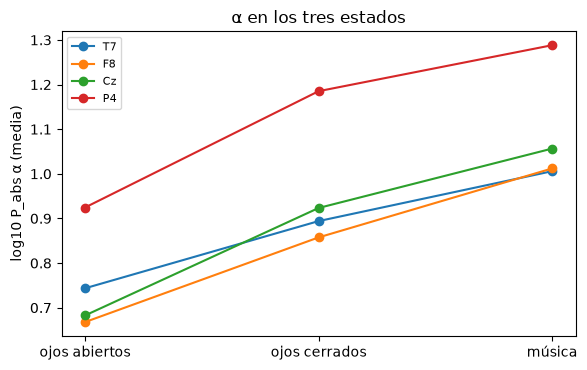

In [53]:
def alfa_log(ruta, patron):
    vals = []
    for s in sujetos:
        ps = [psd_archivo(p)[1] for p in sorted(glob.glob(os.path.join(ruta, patron.format(s=s))))
              if len(eeg.cargar_registro(p)) >= MIN_MUESTRAS]
        vals.append(np.log10(potencia(np.mean(ps, 0), *BANDAS['alfa'])))
    return np.array(vals)                                   # (sujeto, canal)

A = {'ojos abiertos': alfa_log(RUTA_REPOSO_OA, '{s}_ex01_s*.csv'),
     'ojos cerrados': np.log10(potencia(PSD[:, 0], *BANDAS['alfa'])),
     'música': np.log10(potencia(PSD[:, 1], *BANDAS['alfa']))}
tabla_ojos = pd.DataFrame({k: v.mean(0) for k, v in A.items()}, index=CANALES)
display(tabla_ojos.round(2))

fig, ax = plt.subplots(figsize=(6, 3.8))
for k, ch in enumerate(CANALES):
    ax.plot(range(3), [A[c][:, k].mean() for c in A], '-o', label=ch)
ax.set_xticks(range(3), list(A)); ax.set_ylabel('log10 P_abs α (media)')
ax.set_title('α en los tres estados'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Resumen.** La α va **ojos abiertos < ojos cerrados < música** en los 4 electrodos. La música tiene **más** α que el reposo con ojos cerrados, así que lo más probable es que los sujetos escucharan con los ojos cerrados, y el efecto no se explica por los ojos.

## 8.6 Limitaciones

| Limitación | Por qué afecta | Gravedad |
|---|---|---|
| **Aumento global de potencia con música** | Toda la señal sube con música (sobre todo en T7), lo que puede ser orden, auriculares o contacto de electrodos | **Media**: la α absoluta en T7, F8 y P4 se explica por esto |
| **Orden fijo** (reposo al principio, música después) | Relajación o somnolencia con el tiempo suben la α | **Media** (8.3) |
| **Potencia relativa cerrada** (suma 1) | La gran caída de δ hace subir las demás bandas en relativa | **Media**: hay que interpretar la relativa junto con la absoluta |
| **Auriculares solo en la música** | En el reposo no hay auriculares, así que el estímulo auditivo y el dispositivo cambian a la vez | **Media** |
| **Pocos sujetos (n = 19), 4 electrodos** | Limita la detección de efectos chicos y el detalle espacial | **Media** (los efectos principales son grandes) |

## 8.7 Conclusiones

1. **Sí hay un cambio en α, pero es chico.** Con música la α absoluta sube ≈ 25–40 % en los 4 electrodos (significativo en α Cz y T7 con todas las correcciones).
2. **Gran parte de ese aumento es de toda la señal, no solo de α.** Descontando la potencia total, la α sube de forma propia solo en **Cz** (≈ +20 %), y ese resultado está **en el límite** de la significancia (FDR ≈ 0,05).
3. **No lo explican los ojos ni el tiempo.** La α con música es mayor que en reposo con ojos cerrados, y el reposo no cambia entre sesiones.

### Referencias
- Barry, R. J., Clarke, A. R., Johnstone, S. J., Magee, C. A., & Rushby, J. A. (2007). EEG differences between eyes-closed and eyes-open resting conditions. *Clinical Neurophysiology, 118*(12), 2765–2773.
- Abo Alzahab, N., et al. (2021). *Auditory evoked potential EEG-Biometric dataset* (v1.0.0). PhysioNet. https://doi.org/10.13026/ps31-fc50